In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sn

In [58]:
data = pd.read_csv("/kaggle/input/colon-cancer-paper1/export.csv")

/tmp/ipykernel_37/1898073129.py:1: DtypeWarning: Columns (65) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv("/kaggle/input/colon-cancer-paper1/export.csv")


In [59]:
data.head()

,Age recode with <1 year olds,Sex,Year of diagnosis,PRCDA 2020,"Race recode (W, B, AI, API)","Origin recode NHIA (Hispanic, Non-Hisp)","Race and origin recode (NHW, NHB, NHAIAN, NHAPI, Hispanic)",Site recode ICD-O-3/WHO 2008,Behavior code ICD-O-3,TNM 7/CS v0204+ Schema (thru 2017),...,CS site-specific factor 25 (2004-2017 varying by schema),CS version input current (2004-2015),CS version input original (2004-2015),CS version derived (2004-2015),Sequence number,First malignant primary indicator,Primary by international rules,Record number recode,Total number of in situ/malignant tumors for patient,Total number of benign/borderline tumors for patient
0,65-69 years,Male,2000,Not PRCDA,White,Non-Spanish-Hispanic-Latino,Non-Hispanic White,Rectum,Malignant,Rectum,...,Blank(s),Blank(s),Blank(s),Blank(s),2nd of 2 or more primaries,No,Yes,2,2,0
1,35-39 years,Female,2008,Not PRCDA,White,Spanish-Hispanic-Latino,Hispanic (All Races),Rectosigmoid Junction,Malignant,Rectum,...,988,20510,10401,20550,2nd of 2 or more primaries,No,Yes,1,2,0
2,80-84 years,Female,2008,Not PRCDA,White,Non-Spanish-Hispanic-Latino,Non-Hispanic White,Ascending Colon,Malignant,Colon,...,988,20510,10401,20550,2nd of 2 or more primaries,No,Yes,1,2,0
3,65-69 years,Female,2014,Not PRCDA,Asian or Pacific Islander,Non-Spanish-Hispanic-Latino,Non-Hispanic Asian or Pacific Islander,Rectum,Malignant,Rectum,...,988,20550,20550,20550,2nd of 2 or more primaries,No,Yes,1,2,0
4,75-79 years,Male,2004,Not PRCDA,White,Non-Spanish-Hispanic-Latino,Non-Hispanic White,Rectum,Malignant,Rectum,...,988,20510,10100,20550,2nd of 2 or more primaries,No,Yes,1,2,0


In [60]:
print(data.columns)

Index(['Age recode with <1 year olds', 'Sex', 'Year of diagnosis',
       'PRCDA 2020', 'Race recode (W, B, AI, API)',
       'Origin recode NHIA (Hispanic, Non-Hisp)',
       'Race and origin recode (NHW, NHB, NHAIAN, NHAPI, Hispanic)',
       'Site recode ICD-O-3/WHO 2008', 'Behavior code ICD-O-3',
       'TNM 7/CS v0204+ Schema (thru 2017)', 'TNM 7/CS v0204+ Schema recode',
       'AYA site recode 2020 Revision',
       'Lymphoid neoplasm recode 2021 Revision',
       'ICCC site recode 3rd edition/IARC 2017', 'SEER Brain and CNS Recode',
       'Site recode ICD-O-3 2023 Revision',
       'Site recode ICD-O-3 2023 Revision Expanded',
       'CS Schema - AJCC 6th Edition', 'Primary Site - labeled',
       'Primary Site', 'Histologic Type ICD-O-3',
       'Behavior recode for analysis', 'Grade Recode (thru 2017)',
       'Laterality', 'Diagnostic Confirmation', 'ICD-O-3 Hist/behav',
       'ICD-O-3 Hist/behav, malignant', 'Histology recode - broad groupings',
       'ICCC site recode e

In [61]:
data.describe(include='all')

/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pan

,Age recode with <1 year olds,Sex,Year of diagnosis,PRCDA 2020,"Race recode (W, B, AI, API)","Origin recode NHIA (Hispanic, Non-Hisp)","Race and origin recode (NHW, NHB, NHAIAN, NHAPI, Hispanic)",Site recode ICD-O-3/WHO 2008,Behavior code ICD-O-3,TNM 7/CS v0204+ Schema (thru 2017),...,CS site-specific factor 25 (2004-2017 varying by schema),CS version input current (2004-2015),CS version input original (2004-2015),CS version derived (2004-2015),Sequence number,First malignant primary indicator,Primary by international rules,Record number recode,Total number of in situ/malignant tumors for patient,Total number of benign/borderline tumors for patient
count,761697,761697,761697.000000,761697,761697,761697,761697,761697,761697,761697,...,761697,761697,761697,761697,761697,761697,761697,761697.000000,761697.0,761697.000000
unique,19,2,NaN,3,5,2,6,11,1,11,...,2,6,18,2,16,2,2,NaN,25.0,NaN
top,65-69 years,Male,NaN,Not PRCDA,White,Non-Spanish-Hispanic-Latino,Non-Hispanic White,Rectum,Malignant,Colon,...,988,Blank(s),Blank(s),20550,One primary only,Yes,Yes,NaN,1.0,NaN
freq,94760,395040,NaN,529388,605390,679973,527448,167418,761697,444838,...,505646,328786,328786,432911,531822,621816,737986,NaN,479265.0,NaN
mean,NaN,NaN,2009.920451,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.206476,NaN,0.004991
std,NaN,NaN,6.065664,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.501114,NaN,0.072819
min,NaN,NaN,2000.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,0.000000
25%,NaN,NaN,2005.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,0.000000
50%,NaN,NaN,2010.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,0.000000
75%,NaN,NaN,2015.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,0.000000


In [62]:
data = data.replace(['*','-','blank','Blank','Blank(s)','NaN','nan'],'null')

In [63]:
data.isnull().sum()

Age recode with <1 year olds                            0
Sex                                                     0
Year of diagnosis                                       0
PRCDA 2020                                              0
Race recode (W, B, AI, API)                             0
                                                       ..
First malignant primary indicator                       0
Primary by international rules                          0
Record number recode                                    0
Total number of in situ/malignant tumors for patient    0
Total number of benign/borderline tumors for patient    0
Length: 67, dtype: int64

In [64]:
data.drop(['Age recode with <1 year olds'],inplace=True,axis=1)

In [65]:
numerical_columns = data.select_dtypes(include=['float64', 'int64']).columns
for i in numerical_columns:
    data[i].fillna(data[i].median(), inplace=True)

categorical_columns = data.select_dtypes(include=['object']).columns
for i in categorical_columns:
    data[i].fillna(data[i].mode()[0], inplace=True)

/tmp/ipykernel_37/4189766142.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data[i].fillna(data[i].median(), inplace=True)
/tmp/ipykernel_37/4189766142.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 

In [66]:
print(data.isnull().sum())

Sex                                                     0
Year of diagnosis                                       0
PRCDA 2020                                              0
Race recode (W, B, AI, API)                             0
Origin recode NHIA (Hispanic, Non-Hisp)                 0
                                                       ..
First malignant primary indicator                       0
Primary by international rules                          0
Record number recode                                    0
Total number of in situ/malignant tumors for patient    0
Total number of benign/borderline tumors for patient    0
Length: 66, dtype: int64


In [67]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

for column in data.columns:
    if data[column].dtype == 'object':
        data[column] = label_encoder.fit_transform(data[column].astype(str))

In [68]:
columns = data.columns

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/tmp/ipykernel_37/2824997576.py:16: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/tmp/ipykernel_37/2824997576.py:16: UserWarning: The figure layout has changed to tight
  plt.tight_la

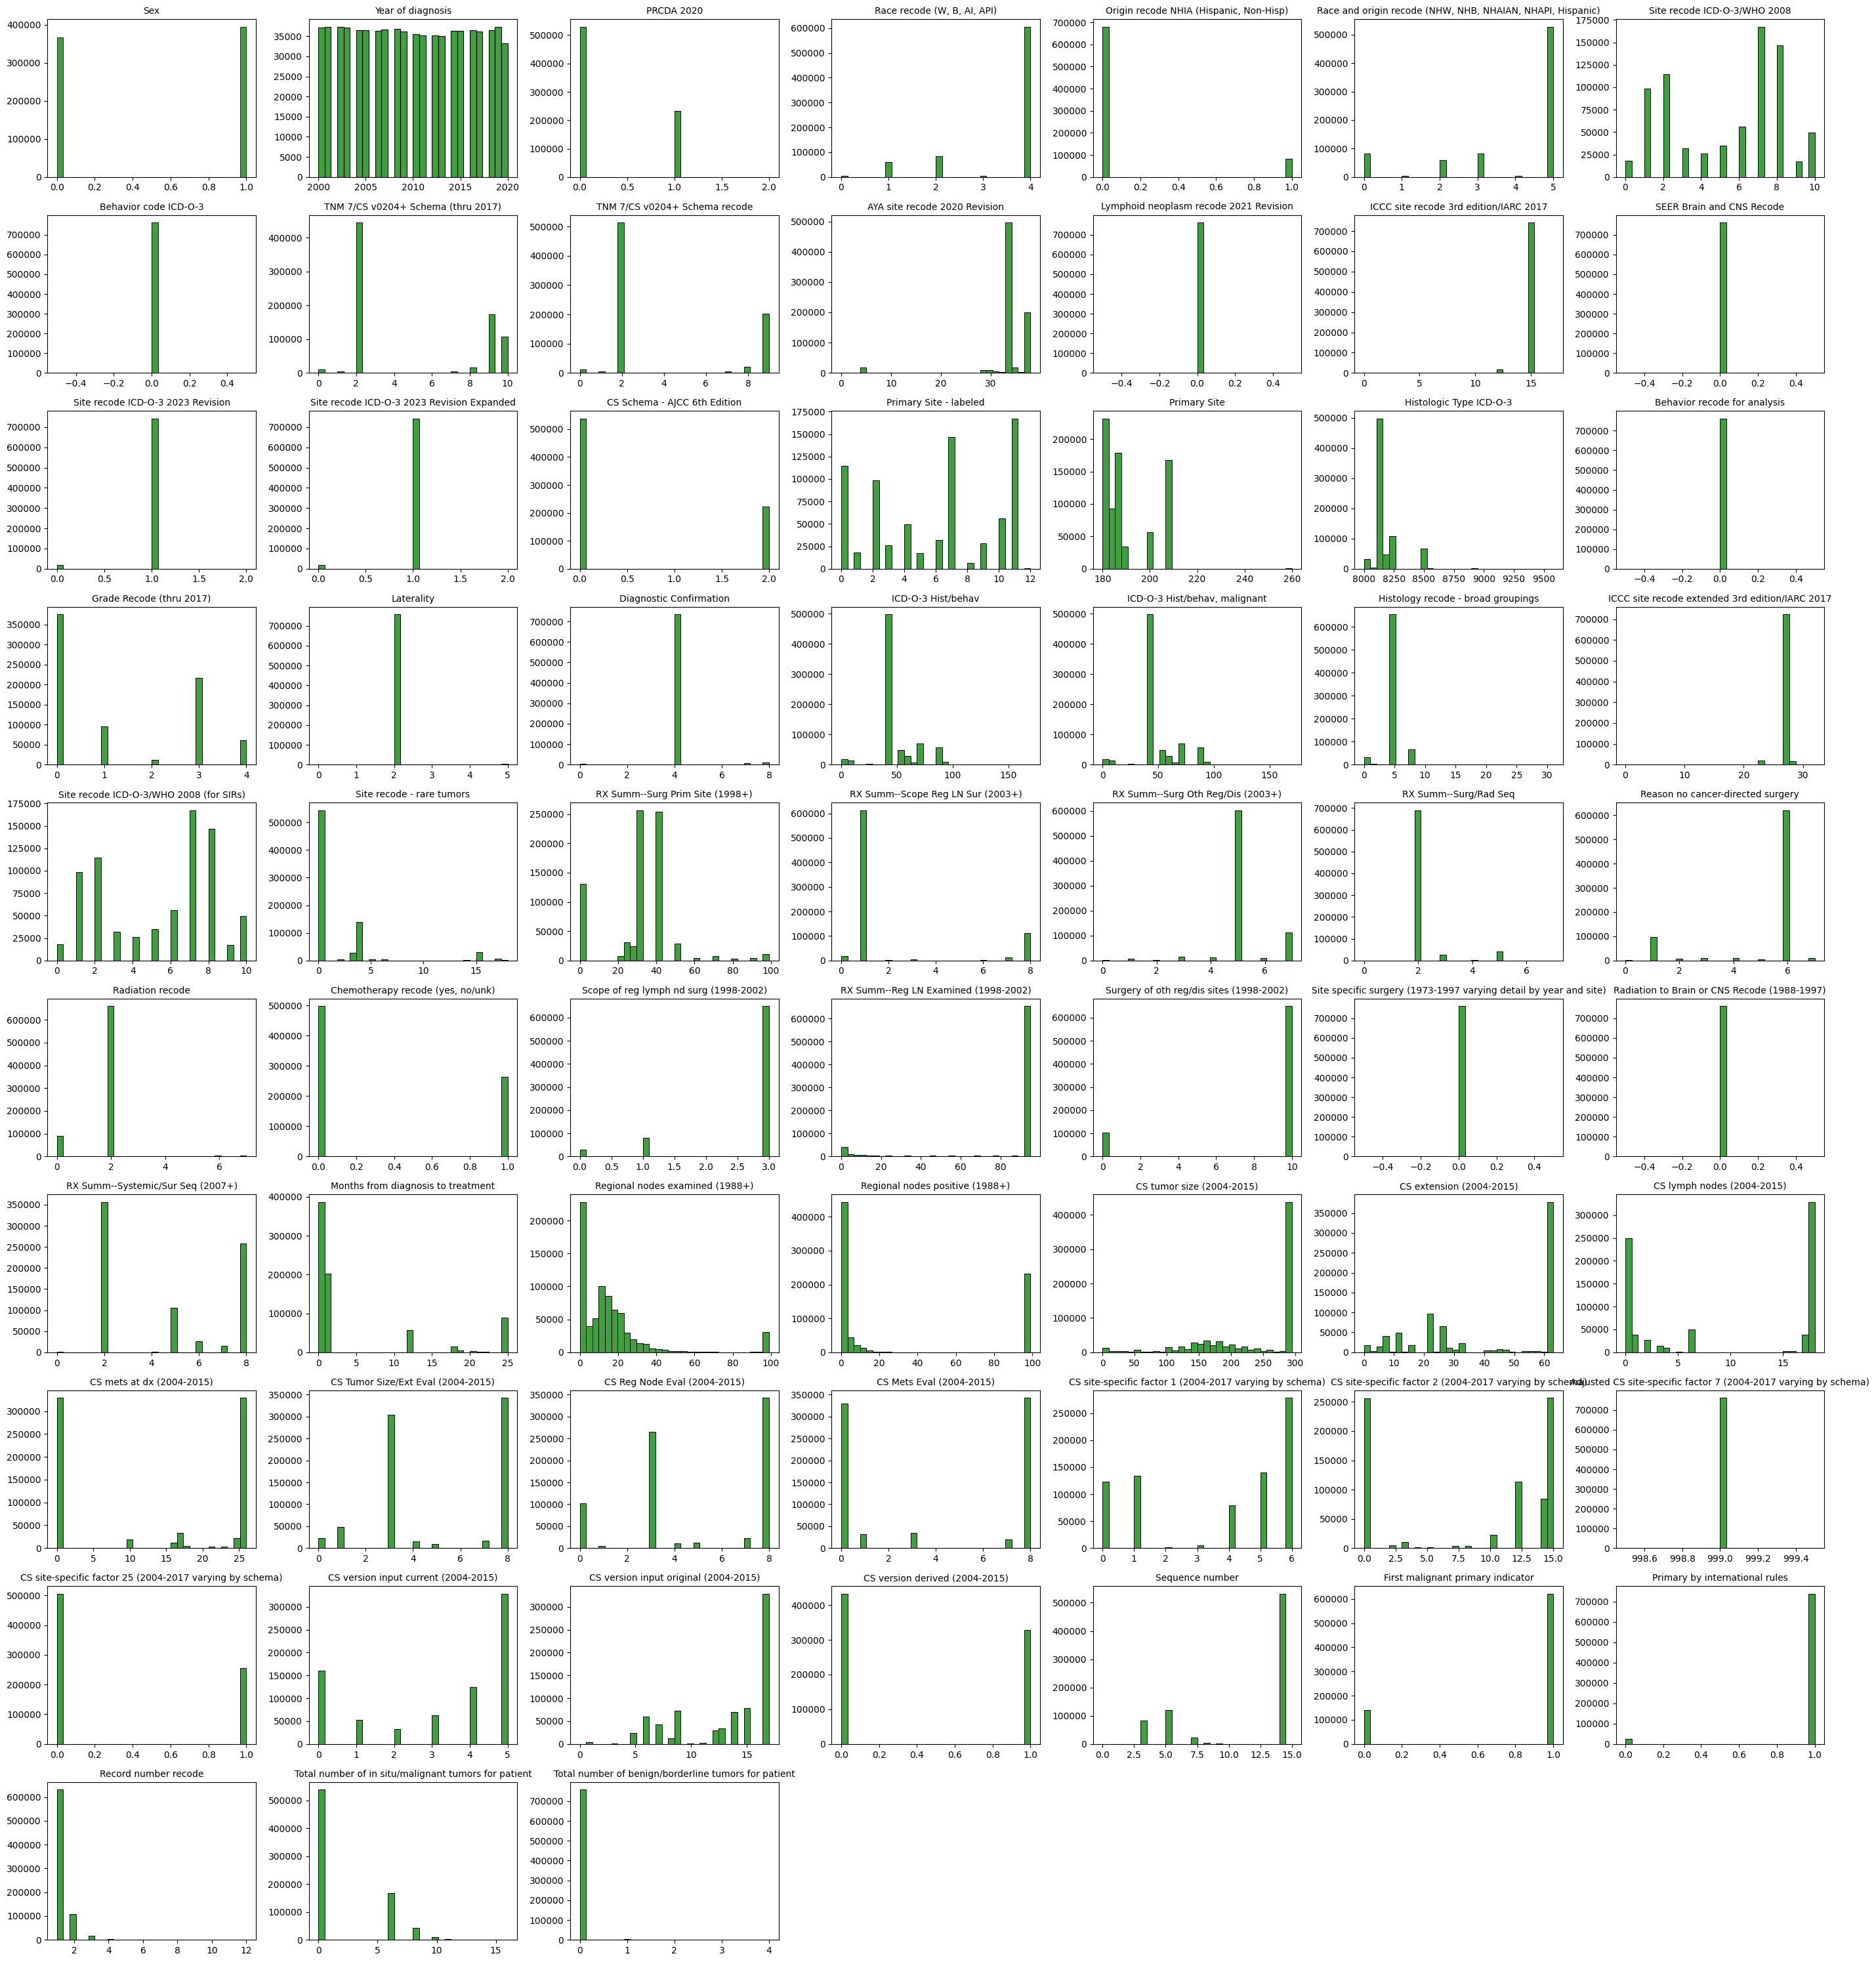

In [69]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = len(columns)
cols_per_row = 7
rows = (num_cols + cols_per_row - 1) // cols_per_row  # Ceiling division

plt.figure(figsize=(cols_per_row * 4, rows * 3))  # Adjust overall figure size

for i in range(num_cols):
    plt.subplot(rows, cols_per_row, i + 1)
    sns.histplot(data[columns[i]].dropna(), bins=30, kde=False, edgecolor='black', color='g')
    plt.title(f'{columns[i]}', fontsize=10)
    plt.xlabel('')
    plt.ylabel('')
    plt.tight_layout()

plt.show()


In [70]:
for col in data.columns:

  Q1 = data[col].quantile(0.25)
  Q3 = data[col].quantile(0.75)
  IQR = Q3 - Q1

  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  outliers = data[~((data[col] >= lower_bound) & (data[col] <= upper_bound))]

  print(f"Number of outliers in column '{col}': {len(outliers)}")

Number of outliers in column 'Sex': 0
Number of outliers in column 'Year of diagnosis': 0
Number of outliers in column 'PRCDA 2020': 0
Number of outliers in column 'Race recode (W, B, AI, API)': 156307
Number of outliers in column 'Origin recode NHIA (Hispanic, Non-Hisp)': 81724
Number of outliers in column 'Race and origin recode (NHW, NHB, NHAIAN, NHAPI, Hispanic)': 0
Number of outliers in column 'Site recode ICD-O-3/WHO 2008': 0
Number of outliers in column 'Behavior code ICD-O-3': 0
Number of outliers in column 'TNM 7/CS v0204+ Schema (thru 2017)': 0
Number of outliers in column 'TNM 7/CS v0204+ Schema recode': 0
Number of outliers in column 'AYA site recode 2020 Revision': 20224
Number of outliers in column 'Lymphoid neoplasm recode 2021 Revision': 0
Number of outliers in column 'ICCC site recode 3rd edition/IARC 2017': 20241
Number of outliers in column 'SEER Brain and CNS Recode': 0
Number of outliers in column 'Site recode ICD-O-3 2023 Revision': 18868
Number of outliers in col

In [71]:
corr_matrix_train = data.corr()
print(corr_matrix_train)

                                                         Sex  \
Sex                                                 1.000000   
Year of diagnosis                                   0.014230   
PRCDA 2020                                          0.003324   
Race recode (W, B, AI, API)                         0.007396   
Origin recode NHIA (Hispanic, Non-Hisp)             0.012653   
...                                                      ...   
First malignant primary indicator                  -0.011912   
Primary by international rules                     -0.000979   
Record number recode                                0.008829   
Total number of in situ/malignant tumors for pa...  0.024902   
Total number of benign/borderline tumors for pa... -0.015943   

                                                    Year of diagnosis  \
Sex                                                          0.014230   
Year of diagnosis                                            1.000000   
PRCDA 2020  

/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


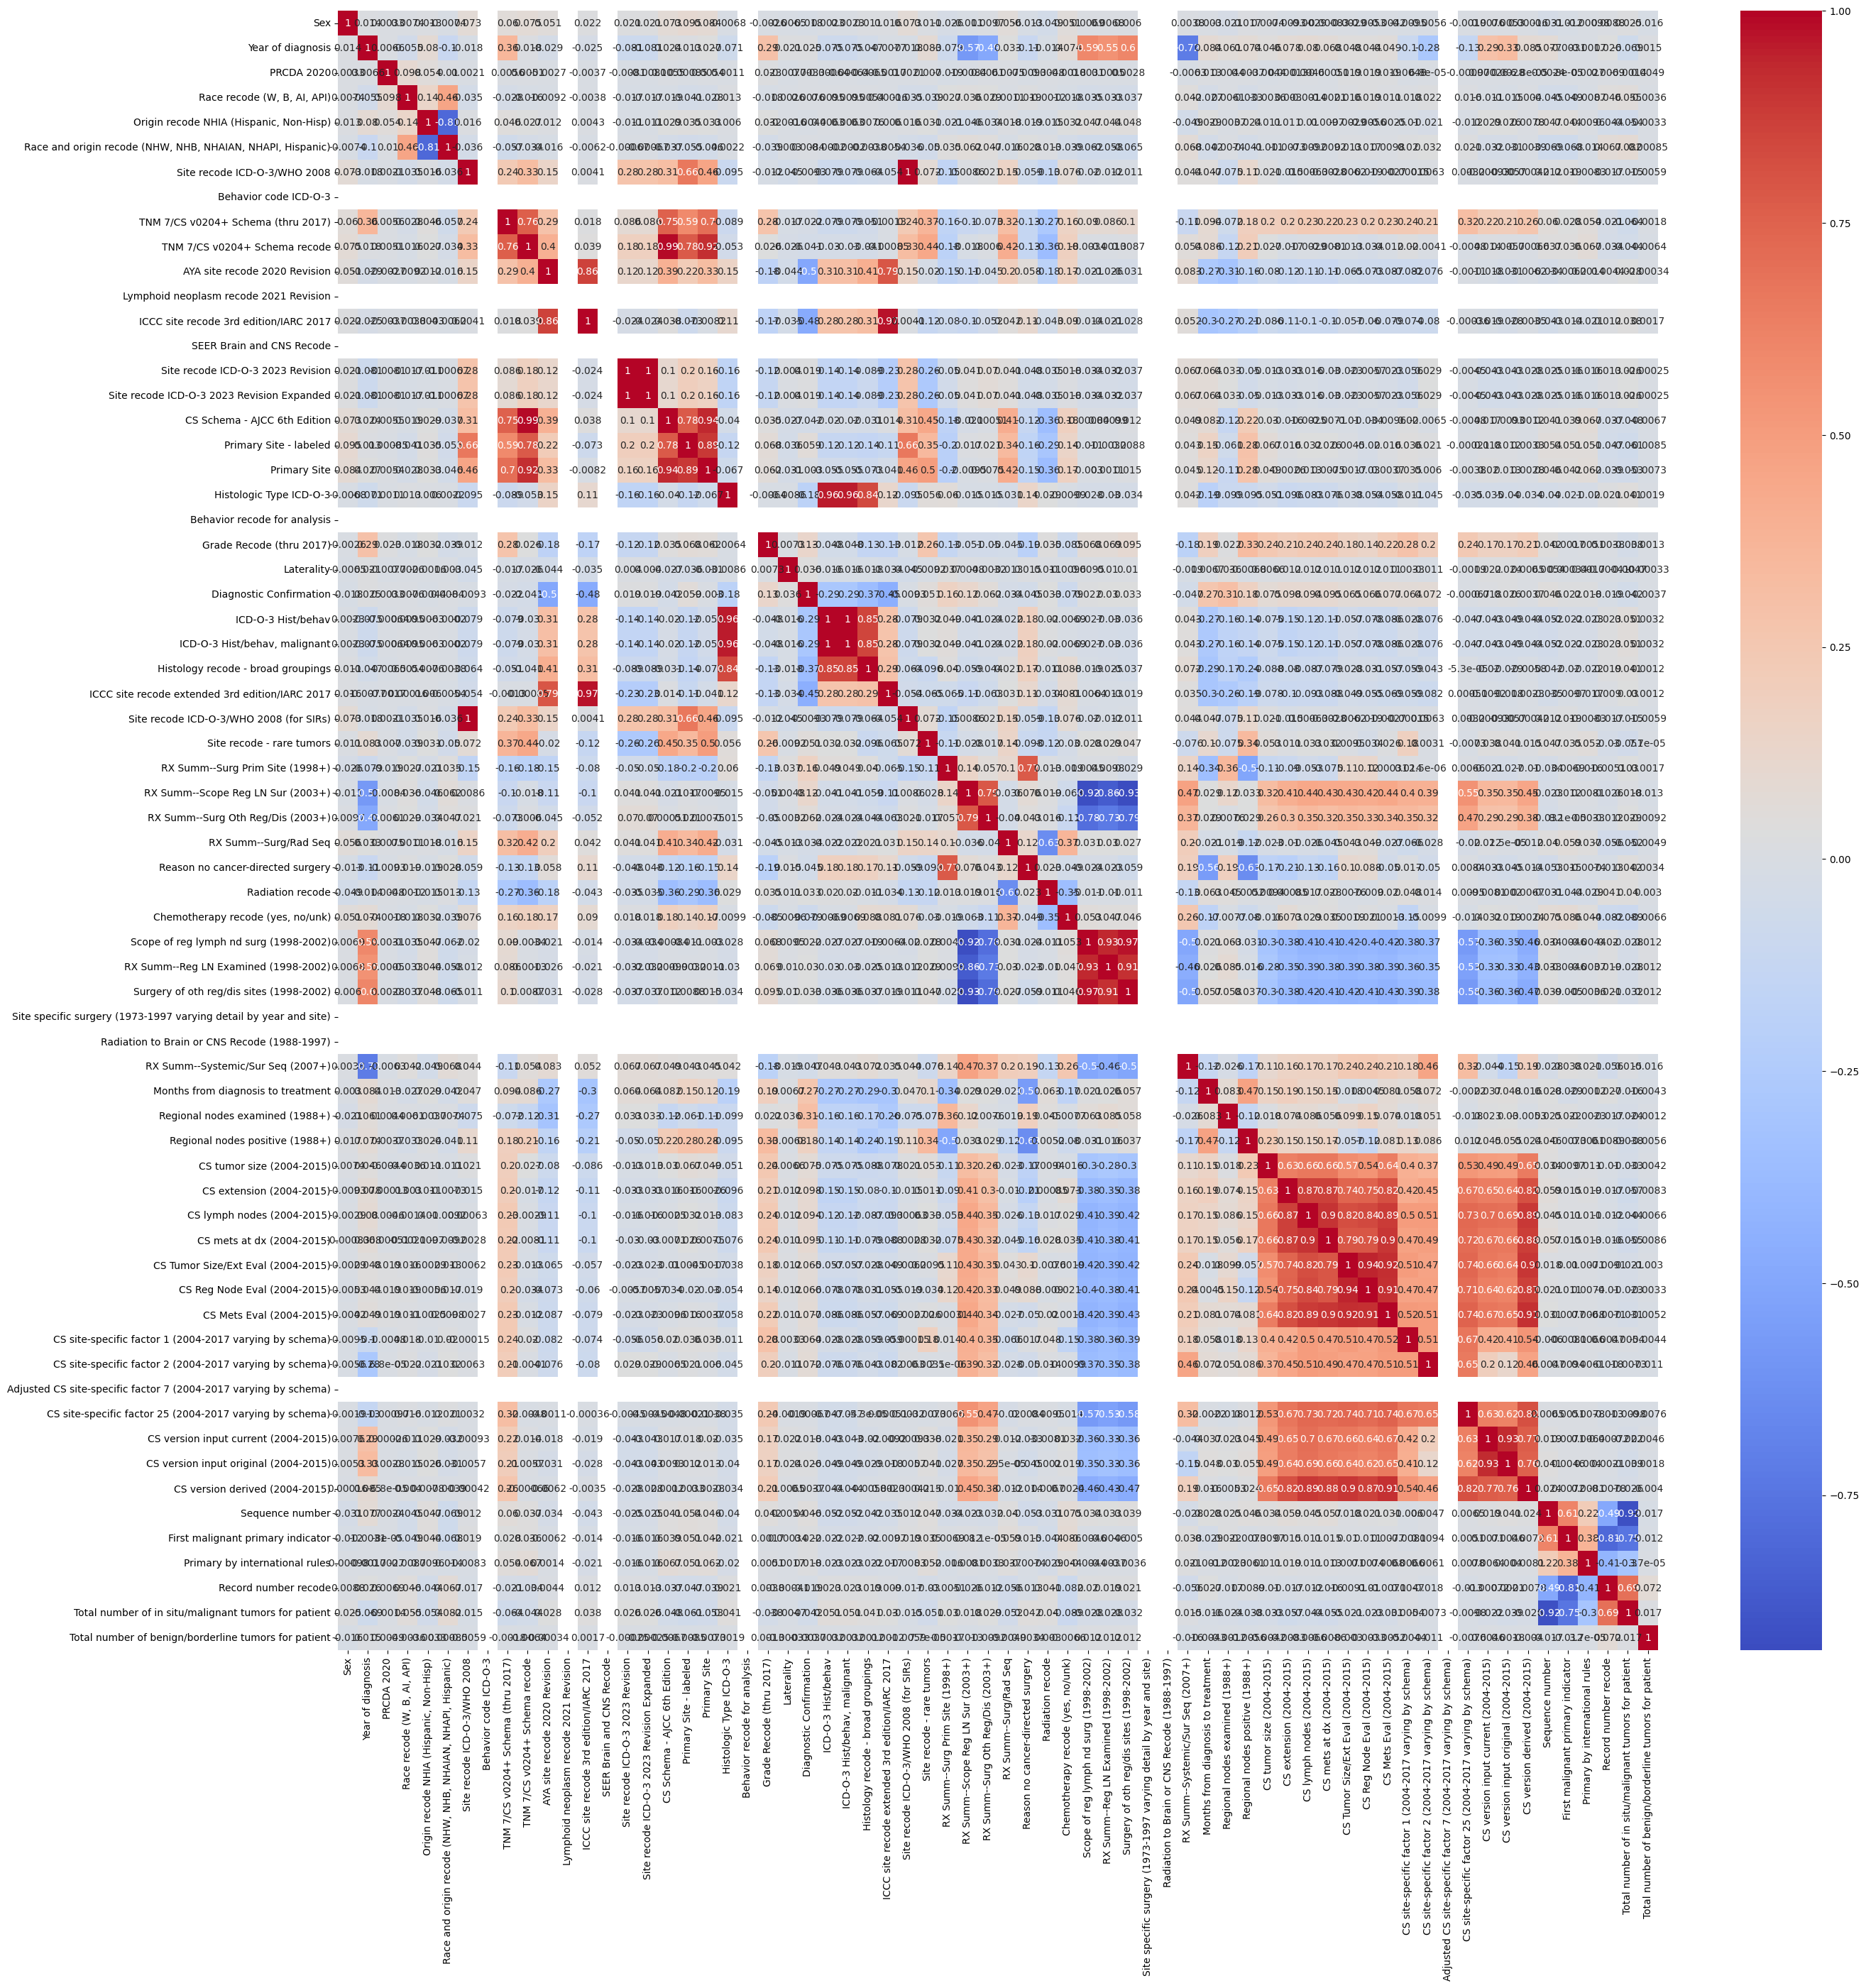

In [72]:
# Correlation Matrix
plt.figure(figsize=(30, 30))
sns.heatmap(corr_matrix_train, annot=True, cmap='coolwarm')
plt.show()

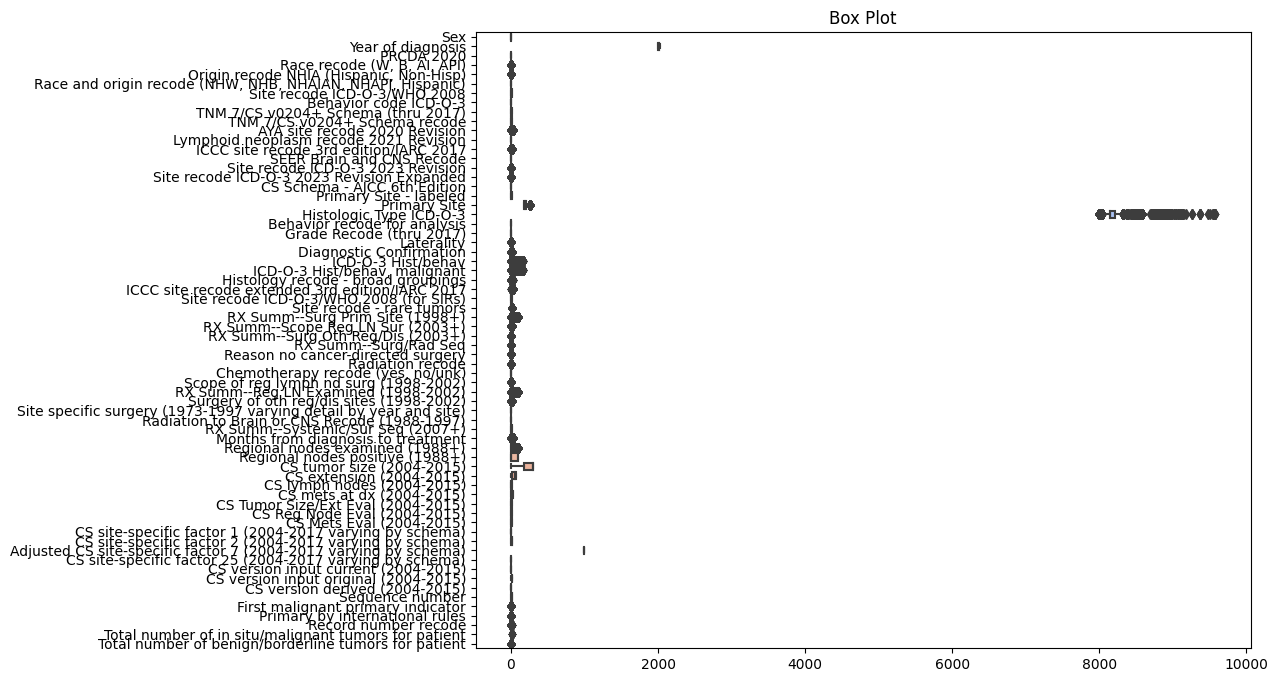

In [73]:
corr_matrix = data.corr()
plt.figure(figsize=(10, 8))
sns.boxplot(data=data, orient='h', palette='coolwarm')
plt.title('Box Plot')
plt.show()

In [74]:
for col in data.columns:
    unique_vals = data[col].unique()
    print(f"\nColumn: {col}")
    print(f"Number of unique values: {len(unique_vals)}")

    print("Unique values:", unique_vals[:10])
    if len(unique_vals) > 10:
        print("... (truncated)")


Column: Sex
Number of unique values: 2
Unique values: [1 0]

Column: Year of diagnosis
Number of unique values: 21
Unique values: [2000 2008 2014 2004 2011 2007 2009 2019 2005 2017]
... (truncated)

Column: PRCDA 2020
Number of unique values: 3
Unique values: [0 1 2]

Column: Race recode (W, B, AI, API)
Number of unique values: 5
Unique values: [4 1 0 2 3]

Column: Origin recode NHIA (Hispanic, Non-Hisp)
Number of unique values: 2
Unique values: [0 1]

Column: Race and origin recode (NHW, NHB, NHAIAN, NHAPI, Hispanic)
Number of unique values: 6
Unique values: [5 0 2 3 1 4]

Column: Site recode ICD-O-3/WHO 2008
Number of unique values: 11
Unique values: [ 7  6  1  0  8  2 10  5  9  3]
... (truncated)

Column: Behavior code ICD-O-3
Number of unique values: 1
Unique values: [0]

Column: TNM 7/CS v0204+ Schema (thru 2017)
Number of unique values: 11
Unique values: [ 9  2  0  8 10  7  5  6  1  3]
... (truncated)

Column: TNM 7/CS v0204+ Schema recode
Number of unique values: 10
Unique valu

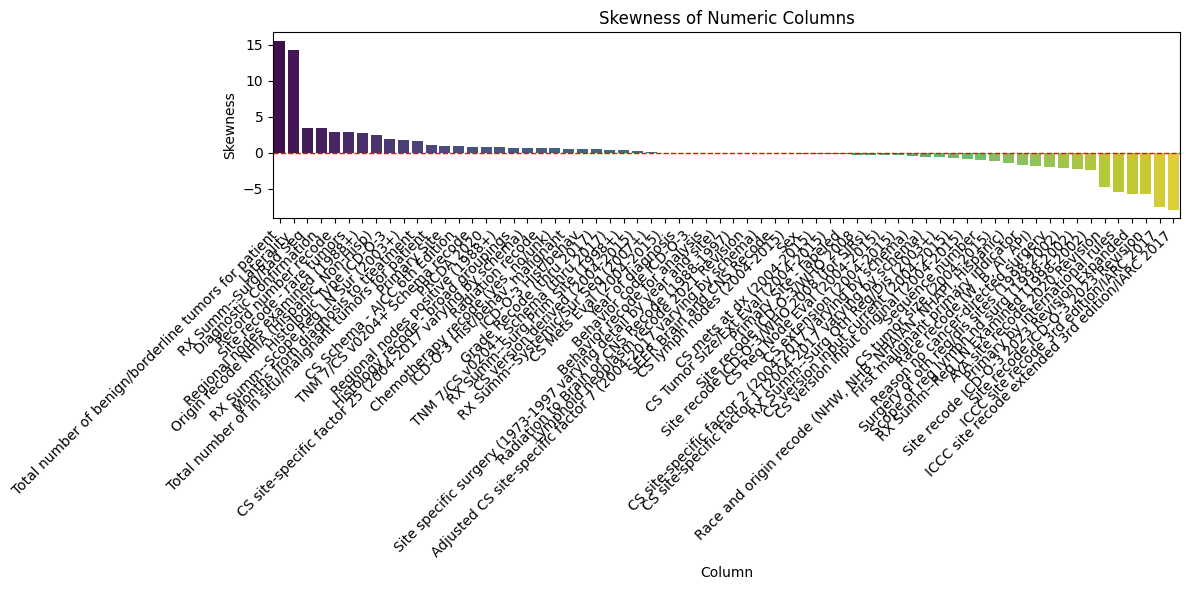

In [75]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

skewness = data.select_dtypes(include=['number']).skew()

skew_df = skewness.sort_values(ascending=False).to_frame(name='Skewness').reset_index()
skew_df.rename(columns={'index': 'Column'}, inplace=True)

# Plot the skewness as a barplot
plt.figure(figsize=(12, 6))
sns.barplot(data=skew_df, x='Column', y='Skewness', palette='viridis')

plt.xticks(rotation=45, ha='right')
plt.axhline(0, color='red', linestyle='--', linewidth=1)
plt.title('Skewness of Numeric Columns')
plt.tight_layout()
plt.show()

In [76]:
X=data.drop([
       'PRCDA 2020',
       'Origin recode NHIA (Hispanic, Non-Hisp)',
       'Site recode ICD-O-3/WHO 2008', 'Behavior code ICD-O-3',
       'AYA site recode 2020 Revision',
       'Lymphoid neoplasm recode 2021 Revision',
       'SEER Brain and CNS Recode',
       'Primary Site - labeled',
       'Grade Recode (thru 2017)',
       'ICD-O-3 Hist/behav',
       'ICD-O-3 Hist/behav, malignant', 'Histology recode - broad groupings',
       'ICCC site recode extended 3rd edition/IARC 2017',
       'RX Summ--Surg Prim Site (1998+)', 'RX Summ--Scope Reg LN Sur (2003+)',
       'RX Summ--Surg Oth Reg/Dis (2003+)', 'Radiation recode',
       'Scope of reg lymph nd surg (1998-2002)',
       'RX Summ--Reg LN Examined (1998-2002)',
       'Surgery of oth reg/dis sites (1998-2002)',
       'Site specific surgery (1973-1997 varying detail by year and site)',
       'Radiation to Brain or CNS Recode (1988-1997)',
       'RX Summ--Systemic/Sur Seq (2007+)',
       'CS tumor size (2004-2015)',
       'CS extension (2004-2015)', 'CS lymph nodes (2004-2015)',
       'CS mets at dx (2004-2015)', 'CS Tumor Size/Ext Eval (2004-2015)',
       'CS Reg Node Eval (2004-2015)', 'CS Mets Eval (2004-2015)',
       'CS site-specific factor 1 (2004-2017 varying by schema)',
       'CS site-specific factor 2 (2004-2017 varying by schema)',
       'Adjusted CS site-specific factor 7 (2004-2017 varying by schema)',
       'CS site-specific factor 25 (2004-2017 varying by schema)',
       'CS version input current (2004-2015)',
       'CS version input original (2004-2015)',
       'CS version derived (2004-2015)', 'Sequence number','First malignant primary indicator'],axis=1)

In [77]:
Y=data['First malignant primary indicator']

In [78]:
print(f"Unique values ({data['First malignant primary indicator'].nunique()}): {data['First malignant primary indicator'].unique()}")

Unique values (2): [0 1]


In [79]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(X,Y,test_size=0.2,random_state=42)

In [80]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,f1_score
# rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf = RandomForestClassifier()
rf.fit(x_train, y_train)
y_pred = rf.predict(x_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%")
f1 = f1_score(y_test, y_pred, average='macro')  # Use 'binary' for binary classification, 'macro'/'micro' for multi-class
print(f"F1 Marco: {f1*100:.2f}")
f1 = f1_score(y_test, y_pred, average='micro')  # Use 'binary' for binary classification, 'macro'/'micro' for multi-class
print(f"F1 Micro: {f1*100:.2f}")

Accuracy: 96.14%
F1 Marco: 93.47
F1 Micro: 96.14


Neural Network

In [81]:
x_train = x_train.astype(np.int32)
y_train = y_train.astype(np.int32)
x_test = x_test.astype(np.int32)
y_test = y_test.astype(np.int32)

In [82]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

In [83]:
model=Sequential()

In [84]:
model.add(Dense(1000, activation='sigmoid',input_dim=64))
model.add(Dense(1000, activation='sigmoid'))
model.add(Dense(1000, activation='sigmoid'))
model.add(Dense(500, activation='sigmoid'))
model.add(Dense(500, activation='sigmoid'))
model.add(Dense(100, activation='sigmoid'))
model.add(Dense(1, activation='sigmoid'))

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [85]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 1000)           │        65,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1000)           │     1,001,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1000)           │     1,001,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 500)            │       500,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 500)            │       250,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 100)            │        50,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,868,201 (10.94 MB)

 Trainable params: 2,868,201 (10.94 MB)

 Non-trainable params: 0 (0.00 B)

In [86]:
import matplotlib.pyplot as plt
import tensorflow as tf

input_dim = x_train.shape[1]

# ----- Model -----
model = tf.keras.Sequential([
    tf.keras.layers.Dense(64, input_shape=(input_dim,), activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# ----- Train model -----
history = model.fit(
    x_train, y_train,
    batch_size=64,
    validation_data=(x_test, y_test),
    epochs=10,
    verbose=1
)

Epoch 1/10
9522/9522 ━━━━━━━━━━━━━━━━━━━━ 26s 3ms/step - accuracy: 0.8297 - loss: 6.2224 - val_accuracy: 0.8495 - val_loss: 1.1007
Epoch 2/10
9522/9522 ━━━━━━━━━━━━━━━━━━━━ 24s 2ms/step - accuracy: 0.9169 - loss: 0.4046 - val_accuracy: 0.8924 - val_loss: 0.2285
Epoch 3/10
9522/9522 ━━━━━━━━━━━━━━━━━━━━ 24s 3ms/step - accuracy: 0.9341 - loss: 0.1833 - val_accuracy: 0.8962 - val_loss: 0.2049
Epoch 4/10
9522/9522 ━━━━━━━━━━━━━━━━━━━━ 23s 2ms/step - accuracy: 0.9475 - loss: 0.1358 - val_accuracy: 0.9650 - val_loss: 0.1039
Epoch 5/10
9522/9522 ━━━━━━━━━━━━━━━━━━━━ 24s 2ms/step - accuracy: 0.9538 - loss: 0.1229 - val_accuracy: 0.9583 - val_loss: 0.1041
Epoch 6/10
9522/9522 ━━━━━━━━━━━━━━━━━━━━ 24s 2ms/step - accuracy: 0.9570 - loss: 0.1156 - val_accuracy: 0.9647 - val_loss: 0.1001
Epoch 7/10
9522/9522 ━━━━━━━━━━━━━━━━━━━━ 23s 2ms/step - accuracy: 0.9591 - loss: 0.1128 - val_accuracy: 0.9626 - val_loss: 0.1015
Epoch 8/10
9522/9522 ━━━━━━━━━━━━━━━━━━━━ 24s 2ms/step - accuracy: 0.9605 - loss: 0

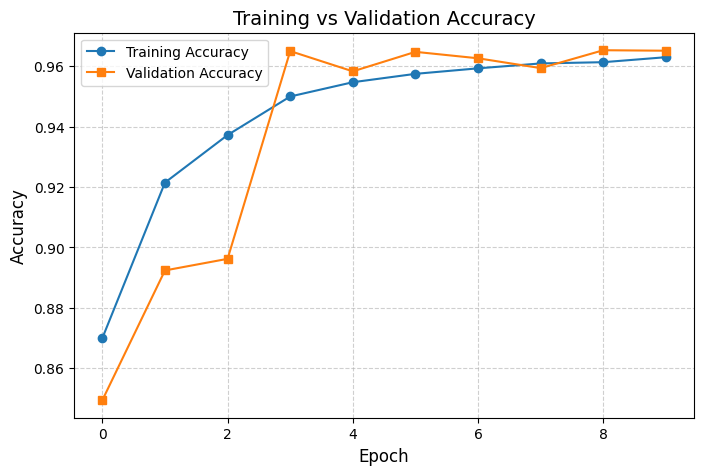

In [87]:
# ----- Plot Accuracy -----
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Training Accuracy', marker='o')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', marker='s')

plt.title("Training vs Validation Accuracy", fontsize=14)
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Accuracy", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

4761/4761 ━━━━━━━━━━━━━━━━━━━━ 6s 1ms/step


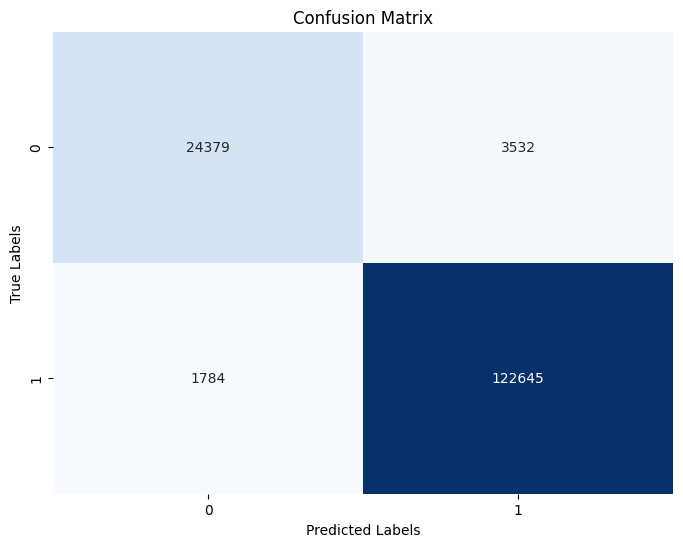

In [88]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt


y_pred = model.predict(x_test)
y_pred_classes = (y_pred > 0.5).astype(int)


cm = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()


# FedAvg

In [89]:
# Save initial (global) model weights
initial_weights = model.get_weights()

# After training locally (on client data)
trained_weights = model.get_weights()

In [90]:
# -----------------------------
# 1️⃣ Create IID Clients
# -----------------------------
def create_iid_clients(X, y, num_clients=5):
    """Split structured dataset into IID partitions for federated simulation."""
    data_per_client = len(X) // num_clients
    clients = {}
    for i in range(num_clients):
        start = i * data_per_client
        end = start + data_per_client if i < num_clients - 1 else len(X)
        clients[f"client_{i+1}"] = (X[start:end], y[start:end])
    return clients

clients_data = create_iid_clients(x_train, y_train, num_clients=5)

for client_name, (x_client, y_client) in clients_data.items():
    print(f"{client_name}: Features {x_client.shape}, Labels {y_client.shape}, Unique={np.unique(y_client)}")

client_1: Features (121871, 27), Labels (121871,), Unique=[0 1]
client_2: Features (121871, 27), Labels (121871,), Unique=[0 1]
client_3: Features (121871, 27), Labels (121871,), Unique=[0 1]
client_4: Features (121871, 27), Labels (121871,), Unique=[0 1]
client_5: Features (121873, 27), Labels (121873,), Unique=[0 1]


In [91]:
# 3️⃣ Federated Learning Parameters
# -----------------------------
NUM_ROUNDS = 10          # more rounds = better convergence
LOCAL_EPOCHS = 3         # train more locally
BATCH_SIZE = 32
GLOBAL_LR = 0.02         # smoother global update
NOISE_STD = 0.001        # minimal noise

print("\n🚀 Starting Federated Training for Structured Data...\n")

global_model = model  # existing NN model
global_weights = global_model.get_weights()


🚀 Starting Federated Training for Structured Data...



In [92]:
# -----------------------------
# Differential Privacy Helper Function
# -----------------------------
import numpy as np

def add_dp_noise(weights, noise_std=0.001):
    """
    Adds minimal Gaussian noise to model weight updates for privacy.
    Smaller noise_std = higher accuracy, larger = more privacy.
    """
    noisy = []
    for w in weights:
        noise = np.random.normal(0, noise_std, w.shape)
        noisy.append(w + noise)
    return noisy


In [93]:
# -----------------------------
# 4️⃣ Federated Learning Loop
# -----------------------------
for rnd in range(NUM_ROUNDS):
    print(f"\n🌍 Federated Round {rnd+1}/{NUM_ROUNDS}")

    local_updates = []
    local_sizes = []

    for client_id, (x_local, y_local) in clients_data.items():
        # Clone the global model for each client
        local_model = tf.keras.models.clone_model(global_model)
        local_model.set_weights(global_weights)
        local_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.002),
                            loss='binary_crossentropy',
                            metrics=['accuracy'])

        # Save initial local weights
        init_local_weights = local_model.get_weights()

        # Local training
        local_model.fit(x_local, y_local, epochs=LOCAL_EPOCHS, batch_size=BATCH_SIZE, verbose=0)

        # Compute local delta
        updated_weights = local_model.get_weights()
        delta = [u - i for u, i in zip(updated_weights, init_local_weights)]

        # Add DP noise
        delta_noisy = add_dp_noise(delta, noise_std=NOISE_STD)

        local_updates.append(delta_noisy)
        local_sizes.append(len(x_local))

        print(f"  ✅ {client_id}: trained on {len(x_local)} samples")



🌍 Federated Round 1/10
  ✅ client_1: trained on 121871 samples
  ✅ client_2: trained on 121871 samples
  ✅ client_3: trained on 121871 samples
  ✅ client_4: trained on 121871 samples
  ✅ client_5: trained on 121873 samples

🌍 Federated Round 2/10
  ✅ client_1: trained on 121871 samples
  ✅ client_2: trained on 121871 samples
  ✅ client_3: trained on 121871 samples
  ✅ client_4: trained on 121871 samples
  ✅ client_5: trained on 121873 samples

🌍 Federated Round 3/10
  ✅ client_1: trained on 121871 samples
  ✅ client_2: trained on 121871 samples
  ✅ client_3: trained on 121871 samples
  ✅ client_4: trained on 121871 samples
  ✅ client_5: trained on 121873 samples

🌍 Federated Round 4/10
  ✅ client_1: trained on 121871 samples
  ✅ client_2: trained on 121871 samples
  ✅ client_3: trained on 121871 samples
  ✅ client_4: trained on 121871 samples
  ✅ client_5: trained on 121873 samples

🌍 Federated Round 5/10
  ✅ client_1: trained on 121871 samples
  ✅ client_2: trained on 121871 samples


In [94]:
 # -----------------------------
# 5️⃣ Federated Averaging (FedAvg)
# -----------------------------
total_samples = sum(local_sizes)
averaged_update = []

for layer_weights in zip(*local_updates):
    weighted_sum = sum(w * s for w, s in zip(layer_weights, local_sizes))
    avg = weighted_sum / total_samples
    averaged_update.append(avg)

# Smooth global update
new_global_weights = [w + GLOBAL_LR * delta for w, delta in zip(global_weights, averaged_update)]
global_weights = new_global_weights
global_model.set_weights(global_weights)

# Evaluate global model after each round
loss, acc = global_model.evaluate(x_test, y_test, verbose=0)
print(f"📊 Round {rnd+1} — Global Accuracy: {acc*100:.2f}%, Loss: {loss:.4f}")


📊 Round 10 — Global Accuracy: 96.51%, Loss: 0.0974


In [95]:
# -----------------------------
# 6️⃣ Final Global Evaluation
# -----------------------------
final_loss, final_acc = global_model.evaluate(x_test, y_test, verbose=0)
print(f"\n✅ Final Global Accuracy: {final_acc*100:.2f}%, Loss: {final_loss:.4f}")


✅ Final Global Accuracy: 96.51%, Loss: 0.0974


4761/4761 ━━━━━━━━━━━━━━━━━━━━ 6s 1ms/step


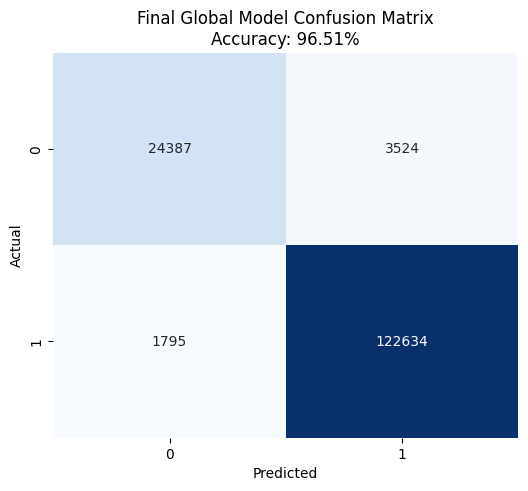

In [96]:
from sklearn.metrics import confusion_matrix

# Confusion Matrix
y_pred = (global_model.predict(x_test) > 0.5).astype(int)
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title(f"Final Global Model Confusion Matrix\nAccuracy: {final_acc*100:.2f}%")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

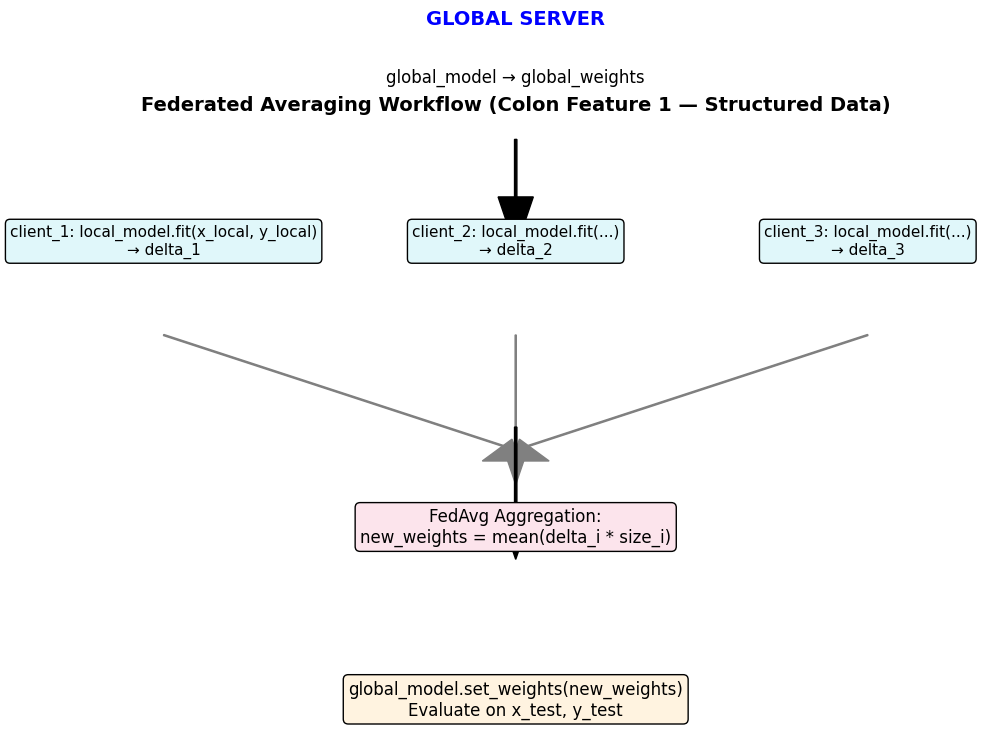

In [97]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

plt.figure(figsize=(10, 6))
plt.text(0.5, 0.9, "GLOBAL SERVER", ha='center', fontsize=14, weight='bold', color='blue')
plt.text(0.5, 0.85, "global_model → global_weights", ha='center', fontsize=12)

plt.text(0.2, 0.7, "client_1: local_model.fit(x_local, y_local)\n→ delta_1", ha='center', fontsize=11, bbox=dict(boxstyle="round", fc="#e0f7fa"))
plt.text(0.5, 0.7, "client_2: local_model.fit(...)\n→ delta_2", ha='center', fontsize=11, bbox=dict(boxstyle="round", fc="#e0f7fa"))
plt.text(0.8, 0.7, "client_3: local_model.fit(...)\n→ delta_3", ha='center', fontsize=11, bbox=dict(boxstyle="round", fc="#e0f7fa"))

plt.arrow(0.5, 0.8, 0, -0.05, width=0.002, head_width=0.03, color='black')
plt.arrow(0.2, 0.63, 0.3, -0.1, width=0.001, head_width=0.02, color='gray')
plt.arrow(0.5, 0.63, 0, -0.1, width=0.001, head_width=0.02, color='gray')
plt.arrow(0.8, 0.63, -0.3, -0.1, width=0.001, head_width=0.02, color='gray')

plt.text(0.5, 0.45, "FedAvg Aggregation:\nnew_weights = mean(delta_i * size_i)", ha='center', fontsize=12, bbox=dict(boxstyle="round", fc="#fce4ec"))
plt.arrow(0.5, 0.55, 0, -0.07, width=0.002, head_width=0.03, color='black')

plt.text(0.5, 0.3, "global_model.set_weights(new_weights)\nEvaluate on x_test, y_test", ha='center', fontsize=12, bbox=dict(boxstyle="round", fc="#fff3e0"))
plt.title("Federated Averaging Workflow (Colon Feature 1 — Structured Data)", fontsize=14, weight='bold')
plt.axis('off')
plt.show()


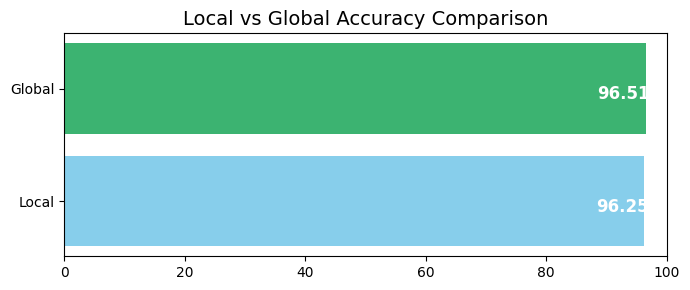

In [99]:
import matplotlib.pyplot as plt

labels = ['Local', 'Global']
values = [96.25, 96.51]
colors = ['skyblue', 'mediumseagreen']

plt.figure(figsize=(7,3))
bars = plt.barh(labels, values, color=colors)

# Annotate values (slightly below the center)
for i, v in enumerate(values):
    plt.text(v - 8, i - 0.05, f"{v}%", color='white',
             va='center', fontsize=12, fontweight='bold')

plt.title("Local vs Global Accuracy Comparison", fontsize=14)
plt.xlim(0, 100)
plt.tight_layout()
plt.show()
